# 12 · 冻结触发条件，分离主波边界、恢复区间与判定时间

旧结果完整保留；旧595个候选ID及触发参数不变。本轮**只新增定位与恢复的工程候选规则**，不重新调20/25µV触发条件，也不对旧人工边界统一减114/225ms。

主波：在独立原始域因果分支上定位。恢复：单独检查正式0.5–30Hz信号。主波结束不表示信号恢复可用，恢复安静条件满足也不证明信号干净。

原始EDF、11号交互窗口、旧自动标注和人工复核文件不修改。所有新产物位于outputs/blink_boundary_localization_v1。

In [2]:
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/blink_boundary_localization.json').exists())
OUT=ROOT/'outputs/blink_boundary_localization_v1'
config=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'run_record.json').read_text())
b=pd.read_csv(OUT/'all_boundaries.csv')
audit=pd.read_csv(OUT/'localization_audit.csv')
summary=pd.read_csv(OUT/'overall_summary.csv')
display(pd.Series(record).drop('config').to_frame('run record'))

,run record
files,12
frozen_candidates,595
detector_config_sha256,eccd8412f204e3270627898baa729d2a9154051f32e503...
frozen_trigger_ids_preserved,True
old_candidate_files_unchanged,True
old_policy_record_unchanged,True
actual_epoch_deletion,False
time_shift_correction,False
recovery_cleanliness_validated,False
main_boundaries_validated,False


## 1. 什么保持不变，什么新增？

旧触发器使用正式分析信号之后的5Hz因果低通：共同额区进入/退出20/10µV、额区幅值≥25µV，以及原有共同变化、持续时间、间距和合并条件，全部保持不变。

新定位分支：**原始EEG → 60Hz notch Q30 → 二阶10Hz因果低通，无新增高通**。它独立于正式分析和旧触发分支，减少再用同一高通反向恢复波定义主波边界的问题。采集端原有滤波已经在原始EDF中，新增分支不能还原采集前的波形，也不能消除所有时序差异。

新分支仍有自身因果延迟，因此新边界不等同于生理真值。后面提供相同分支上的人工标注入口；旧原始域人工标注只作并列参考。

In [3]:
display(pd.Series(config,name='provisional localization settings').to_frame())

,provisional localization settings
version,boundary_localization_v1
status,unvalidated morphology localization; frozen de...
localization_branch,"{'input': 'raw EEG, independent from official/..."
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"
baseline_start_before_trigger_seconds,0.9
baseline_end_before_trigger_seconds,0.55
peak_search_before_trigger_seconds,0.4
peak_search_after_trigger_seconds,0.3
onset_lookback_seconds,0.7
onset_fraction_of_peak,0.15


## 2. 主波定位：历史回溯不等于提前输出

旧触发点之前0.9–0.55秒的历史估计局部基线；在触发前0.4秒至后0.3秒范围内选主要额区偏离峰，允许正负极性。相对该峰回溯最多0.7秒寻找安静后开始偏离的起点；峰后寻找主波回到基线附近的时刻。边界阈值为峰幅15%、下限5µV，安静确认分别0.04/0.06秒。

这些是待验证定位参数，不是新的检测门槛。为检查相邻同极性主波，还查看峰后至0.8秒的局部波形，相关观察时间包含在main_decision_seconds中。回溯起点仅描述波形位置，绝不替代判定时间。

参考区不足、峰在搜索边缘、原始域波形太弱、主波端点找不到、持续时间异常、疑似相邻多波峰或非有限恢复影响时，都标记不确定。没有因为旧检测成功就强行宣布边界可信。

In [4]:
fields=['edf_name','blink_candidate_id','trigger_crossing_seconds','old_onset_seconds','old_offset_seconds',
        'main_onset_seconds','main_peak_seconds','main_offset_seconds','main_decision_seconds',
        'recovery_onset_seconds','recovery_offset_seconds','decision_seconds','decision_available','actual_decision_seconds',
        'localization_usable_for_provisional_comparison','localization_flags']
display(b[fields].head(15))

,edf_name,blink_candidate_id,trigger_crossing_seconds,old_onset_seconds,old_offset_seconds,main_onset_seconds,main_peak_seconds,main_offset_seconds,main_decision_seconds,recovery_onset_seconds,recovery_offset_seconds,decision_seconds,decision_available,actual_decision_seconds,localization_usable_for_provisional_comparison,localization_flags
0,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_B0001,1.414062,1.414062,2.054688,0.769531,1.261719,1.371094,2.207031,1.371094,2.871094,2.867188,True,2.867188,True,NaN
1,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_B0002,108.761719,108.761719,109.355469,108.171875,108.597656,108.765625,109.507812,108.765625,109.789062,109.906250,True,109.906250,True,NaN
2,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_B0003,212.421875,212.421875,212.570312,212.351562,212.613281,212.804688,213.414062,212.804688,213.101562,213.414062,True,213.414062,True,NaN
3,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0001,0.140625,0.140625,0.261719,0.062500,0.347656,1.152344,1.148438,1.152344,1.695312,1.812500,True,1.812500,False,baseline_left_censored;main_offset_unconfirmed
4,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0002,0.500000,0.500000,0.820312,0.062500,0.347656,1.152344,1.148438,1.152344,1.695312,1.812500,True,1.812500,False,baseline_left_censored;main_offset_unconfirmed
5,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0003,4.191406,4.191406,4.734375,3.789062,4.089844,4.132812,4.890625,4.132812,4.730469,4.890625,True,4.890625,True,NaN
6,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0004,87.410156,87.410156,87.984375,87.359375,87.480469,87.734375,88.281250,87.734375,88.222656,88.339844,True,88.339844,True,NaN
7,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0005,106.148438,106.148438,106.335938,106.132812,106.292969,106.519531,107.093750,106.519531,106.687500,107.093750,True,107.093750,True,NaN
8,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0006,126.917969,126.917969,127.039062,126.625000,126.718750,126.851562,127.519531,126.851562,127.757812,127.875000,True,127.875000,True,NaN
9,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_B0001,2.042969,2.042969,2.445312,1.976562,2.062500,2.195312,2.863281,2.195312,2.296875,2.863281,True,2.863281,True,NaN


## 3. 恢复区间：在正式分析信号上单独判断

从主波结束起，在正式0.5–30Hz额区共同波形上观察。相对局部历史基线的偏离降到max(10µV,正式主波峰值20%)以内，并持续0.12秒，才标记quiet_criterion_met_unvalidated。最大观察1.5秒；没满足则标not_confirmed_within_horizon，文件结束不足则另标。

这只是一套有限时间、额区范围内的安静指标，**不证明16通道恢复可用**。反向波、尾波、真实脑电与眼动影响无法靠此规则完全区分。保存全部16通道在恢复区间的PTP，供后续核查；绝不因主波结束就把尾波自动视为正常。

恢复区间末端是安静窗口开始，decision仍需等待安静窗口结束及其他所需观察。若判定所需数据尚未到齐，decision_available=False、actual_decision_seconds留空；预计所需时间不能被称为已实际完成判断。

In [5]:
display(b.groupby('recovery_status').size().rename('candidates').to_frame())
display(b[['blink_candidate_id','recovery_duration_seconds','recovery_criterion_uv','recovery_channels','recovery_ptp_by_channel_uv']].head(8))
assert not b.recovery_proves_clean_signal.any()

,candidates
recovery_status,
not_confirmed_within_horizon,106
quiet_criterion_met_unvalidated,488
unconfirmed_at_eof,1


,blink_candidate_id,recovery_duration_seconds,recovery_criterion_uv,recovery_channels,recovery_ptp_by_channel_uv
0,F_03_SE001_CBCol_Train01_B0001,1.500000,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 77.71422413247234, ""EEG_Fz"": 73.896..."
1,F_03_SE001_CBCol_Train01_B0002,1.023438,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 75.69263078918124, ""EEG_Fz"": 68.646..."
2,F_03_SE001_CBCol_Train01_B0003,0.296875,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 56.975529556206354, ""EEG_Fz"": 56.51..."
3,F_03_SE002_CBCol_Train01_B0001,0.542969,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 35.165518394546375, ""EEG_Fz"": 31.35..."
4,F_03_SE002_CBCol_Train01_B0002,0.542969,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 35.165518394546375, ""EEG_Fz"": 31.35..."
5,F_03_SE002_CBCol_Train01_B0003,0.597656,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 62.949400553247266, ""EEG_Fz"": 55.20..."
6,F_03_SE002_CBCol_Train01_B0004,0.488281,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 59.24352649019113, ""EEG_Fz"": 55.696..."
7,F_03_SE002_CBCol_Train01_B0005,0.167969,10.0,EEG_F3;EEG_Fz;EEG_F4,"{""EEG_F3"": 23.396479561291173, ""EEG_Fz"": 20.35..."


## 4. 不确定定位与旧区间回退

595个触发中，428个通过本轮定位的内部形态检查，167个标记不确定；“通过内部检查”不代表已被人工验证准确。

用于epoch损失对照时，不确定候选**回退旧区间**，而不是因找不到边界而把该候选删除。原始main/recovery估计也保留作诊断，图上不确定主波用红色，不能误当作已采纳的橙色主波。

相邻主波、多触发定位到接近同一峰、主波起点相对旧候选次序倒置、恢复区间与下一主波相交，分别报告。跨候选审计为回顾性诊断，不参与实时边界或拒绝判定，不静默合并/拆分旧ID。

In [6]:
display(audit)
flags=b.localization_flags.fillna('').str.get_dummies(sep=';').sum().sort_values(ascending=False)
display(flags.rename('candidates').to_frame())
display(pd.read_csv(OUT/'possible_merged_lobes.csv').head(15))

,edf_name,n_candidates,localized_main_usable,old_fallback_candidates,possible_multi_lobe_candidates,near_duplicate_peak_candidates,main_onset_order_inversions,recovery_not_confirmed,new_policy_conservative_extra_wait_seconds
0,F_03_SE001_CBCol_Train01.edf,3,3,0,0,0,0,1,3.824219
1,F_03_SE002_CBCol_Train01.edf,6,4,2,0,2,0,0,3.824219
2,F_05_SE001_CBCol_Train02.edf,95,81,14,10,2,1,15,3.824219
3,F_05_SE002_CBCol_Train01.edf,102,83,19,7,0,0,8,3.824219
4,F_06_SE001_CBCol_Train01.edf,2,1,1,0,0,0,2,3.824219
5,F_06_SE002_CBCol_Train01.edf,0,0,0,0,0,0,0,3.824219
6,F_20_SE001_CBCol_Train01.edf,6,4,2,2,0,0,6,3.824219
7,F_20_SE002_CBCol_Train01.edf,12,7,5,4,0,0,9,3.824219
8,F_05_SE002_CBCol_Train02.edf,126,100,26,13,0,0,13,3.824219
9,F_05_SE003_CBCol_Train04.edf,140,110,30,21,6,2,17,3.824219


,candidates
possible_adjacent_main_lobes,117
main_offset_unconfirmed,49
main_duration_outside_bounds,19
peak_at_search_edge,9
baseline_left_censored,5
main_onset_left_censored,5
weak_raw_domain_waveform,2


,blink_candidate_id,first_peak_sample,second_peak_sample,first_peak_seconds,second_peak_seconds,action,edf_name
0,F_05_SE001_CBCol_Train02_B0011,8177,8329,31.941406,32.535156,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
1,F_05_SE001_CBCol_Train02_B0041,23955,24022,93.574219,93.835938,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
2,F_05_SE001_CBCol_Train02_B0050,30407,30502,118.777344,119.148438,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
3,F_05_SE001_CBCol_Train02_B0067,42439,42609,165.777344,166.441406,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
4,F_05_SE001_CBCol_Train02_B0086,52866,52908,206.507812,206.671875,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
5,F_05_SE001_CBCol_Train02_B0090,54603,54722,213.292969,213.757812,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
6,F_05_SE001_CBCol_Train02_B0091,54722,54856,213.757812,214.281250,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
7,F_05_SE001_CBCol_Train02_B0092,54856,55013,214.281250,214.894531,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
8,F_05_SE001_CBCol_Train02_B0094,55239,55360,215.777344,216.250000,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf
9,F_05_SE001_CBCol_Train02_B0095,55523,55589,216.886719,217.144531,flag only; no automatic merge or split,F_05_SE001_CBCol_Train02.edf


## 5. 检查是否把主波切得太短

下表将同一父候选的新主波时长与旧区间时长并列。仅对内部检查通过的定位统计，并列出最短的若干例，不把“更短”当作成功标准。

持续时间至少0.08秒只是工程约束，不能证明0.09秒就足够；短主波、多个真实眨眼相近、局部基线受前次眨眼污染等情形，仍需要在同一分支上人工核对。

old_duration_seconds                      \
                                            count    median       min   
edf_name                                                                
F_03_SE001_CBCol_Train01.edf                    3  0.593750  0.148438   
F_03_SE002_CBCol_Train01.edf                    4  0.365234  0.121094   
F_05_SE001_CBCol_Train02.edf                   81  0.363281  0.085938   
F_05_SE002_CBCol_Train01.edf                   83  0.429688  0.171875   
F_05_SE002_CBCol_Train02.edf                  100  0.451172  0.171875   
F_05_SE003_CBCol_Train04.edf                  110  0.439453  0.089844   
F_06_SE001_CBCol_Train01.edf                    1  0.261719  0.261719   
F_08_SE003_CBCol_Train03.edf                   24  0.462891  0.308594   
F_20_SE001_CBCol_Train01.edf                    4  0.410156  0.195312   
F_20_SE002_CBCol_Train01.edf                    7  0.472656  0.117188   
F_25_SE001_CBCol_Train01.edf                   11  0.351562  0.093750   

                                       main_duration_seconds            \
                                   max                 count    median   
edf_name                                                                 
F_03_SE001_CBCol_Train01.edf  0.640625                     3  0.593750   
F_03_SE002_CBCol_Train01.edf  0.574219                     4  0.359375   
F_05_SE001_CBCol_Train02.edf  1.070312                    81  0.175781   
F_05_SE002_CBCol_Train01.edf  1.050781                    83  0.210938   
F_05_SE002_CBCol_Train02.edf  1.187500                   100  0.203125   
F_05_SE003_CBCol_Train04.edf  1.187500                   110  0.242188   
F_06_SE001_CBCol_Train01.edf  0.261719                     1  0.753906   
F_08_SE003_CBCol_Train03.edf  1.164062                    24  0.187500   
F_20_SE001_CBCol_Train01.edf  0.687500                     4  0.347656   
F_20_SE002_CBCol_Train01.edf  0.714844                     7  0.335938   
F_25_SE001_CBCol_Train01.edf  0.863281                    11  0.175781   

                                                 recovery_duration_seconds  \
                                   min       max                     count   
edf_name                                                                     
F_03_SE001_CBCol_Train01.edf  0.453125  0.601562                         3   
F_03_SE002_CBCol_Train01.edf  0.226562  0.386719                         4   
F_05_SE001_CBCol_Train02.edf  0.085938  0.914062                        81   
F_05_SE002_CBCol_Train01.edf  0.089844  0.843750                        83   
F_05_SE002_CBCol_Train02.edf  0.085938  1.074219                       100   
F_05_SE003_CBCol_Train04.edf  0.105469  0.906250                       110   
F_06_SE001_CBCol_Train01.edf  0.753906  0.753906                         1   
F_08_SE003_CBCol_Train03.edf  0.105469  1.003906                        24   
F_20_SE001_CBCol_Train01.edf  0.160156  0.421875                         4   
F_20_SE002_CBCol_Train01.edf  0.175781  0.832031                         7   
F_25_SE001_CBCol_Train01.edf  0.085938  0.417969                        11   

                                                           
                                median       min      max  
edf_name                                                   
F_03_SE001_CBCol_Train01.edf  1.023438  0.296875  1.50000  
F_03_SE002_CBCol_Train01.edf  0.542969  0.167969  0.90625  
F_05_SE001_CBCol_Train02.edf  0.570312  0.000000  1.50000  
F_05_SE002_CBCol_Train01.edf  0.250000  0.000000  1.50000  
F_05_SE002_CBCol_Train02.edf  0.269531  0.000000  1.50000  
F_05_SE003_CBCol_Train04.edf  0.457031  0.000000  1.50000  
F_06_SE001_CBCol_Train01.edf  1.500000  1.500000  1.50000  
F_08_SE003_CBCol_Train03.edf  0.212891  0.000000  1.50000  
F_20_SE001_CBCol_Train01.edf  1.500000  1.500000  1.50000  
F_20_SE002_CBCol_Train01.edf  1.500000  0.164062  1.50000  
F_25_SE001_CBCol_Train01.edf  0.796875  0.062500  1.50000

,edf_name,blink_candidate_id,main_onset_seconds,main_offset_seconds,main_duration_seconds
565,F_25_SE001_CBCol_Train01.edf,F_25_SE001_CBCol_Train01_B0041,141.875000,141.960938,0.085938
20,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_B0012,37.648438,37.734375,0.085938
244,F_05_SE002_CBCol_Train02.edf,F_05_SE002_CBCol_Train02_B0019,38.476562,38.562500,0.085938
167,F_05_SE002_CBCol_Train01.edf,F_05_SE002_CBCol_Train01_B0064,142.707031,142.796875,0.089844
585,F_25_SE001_CBCol_Train01.edf,F_25_SE001_CBCol_Train01_B0061,198.542969,198.636719,0.093750
24,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_B0016,50.835938,50.933594,0.097656
294,F_05_SE002_CBCol_Train02.edf,F_05_SE002_CBCol_Train02_B0069,126.804688,126.906250,0.101562
569,F_25_SE001_CBCol_Train01.edf,F_25_SE001_CBCol_Train01_B0045,152.718750,152.824219,0.105469
41,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_B0033,79.296875,79.402344,0.105469
505,F_08_SE003_CBCol_Train03.edf,F_08_SE003_CBCol_Train03_B0014,85.253906,85.359375,0.105469


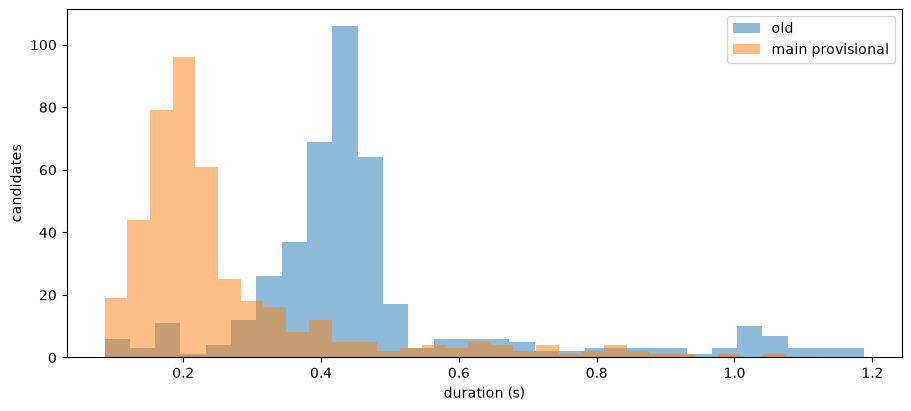

In [7]:
good=b[b.localization_usable_for_provisional_comparison].copy()
good['old_duration_seconds']=good.old_offset_seconds-good.old_onset_seconds
display(good.groupby('edf_name')[['old_duration_seconds','main_duration_seconds','recovery_duration_seconds']].agg(['count','median','min','max']))
display(good.sort_values('main_duration_seconds')[['edf_name','blink_candidate_id','main_onset_seconds','main_offset_seconds','main_duration_seconds']].head(10))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.hist(good.old_duration_seconds,bins=30,alpha=.5,label='old')
ax.hist(good.main_duration_seconds,bins=30,alpha=.5,label='main provisional')
ax.set(xlabel='duration (s)',ylabel='candidates');ax.legend();plt.show()

## 6. 同时看四个信号域，不做统一时间平移

下面固定展示两份完整复核文件的首个非启动候选、首个形态警告，以及此前检查的F05 B0010反向恢复疑似误报。

每图依次为原始EEG、新定位分支、正式0.5–30Hz、旧5Hz触发分支。同一主波/恢复边界叠加到四域便于辨别相位与形态影响，但**应在新定位分支上判断新主波边界是否合理，在正式分析信号上判断尾波是否仍有影响**。

绿色是历史原始域人工标注；灰色旧区间、橙色暂定主波、紫色恢复、红色不确定主波。虚线为判定时间，不是波形起点。图中有些判定晚于主波很多，这是实际用到后续观察信息的结果，不往前伪装时间。

,edf_name,blink_candidate_id,figure,selection,main_usable
0,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0008,F_05_SE003_CBCol_Train04\F_05_SE003_CBCol_Trai...,"earliest nonstartup, first warning, and previo...",True
1,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0010,F_05_SE003_CBCol_Train04\F_05_SE003_CBCol_Trai...,"earliest nonstartup, first warning, and previo...",False
2,F_08_SE003_CBCol_Train03.edf,F_08_SE003_CBCol_Train03_B0003,F_08_SE003_CBCol_Train03\F_08_SE003_CBCol_Trai...,"earliest nonstartup, first warning, and previo...",True
3,F_08_SE003_CBCol_Train03.edf,F_08_SE003_CBCol_Train03_B0009,F_08_SE003_CBCol_Train03\F_08_SE003_CBCol_Trai...,"earliest nonstartup, first warning, and previo...",False


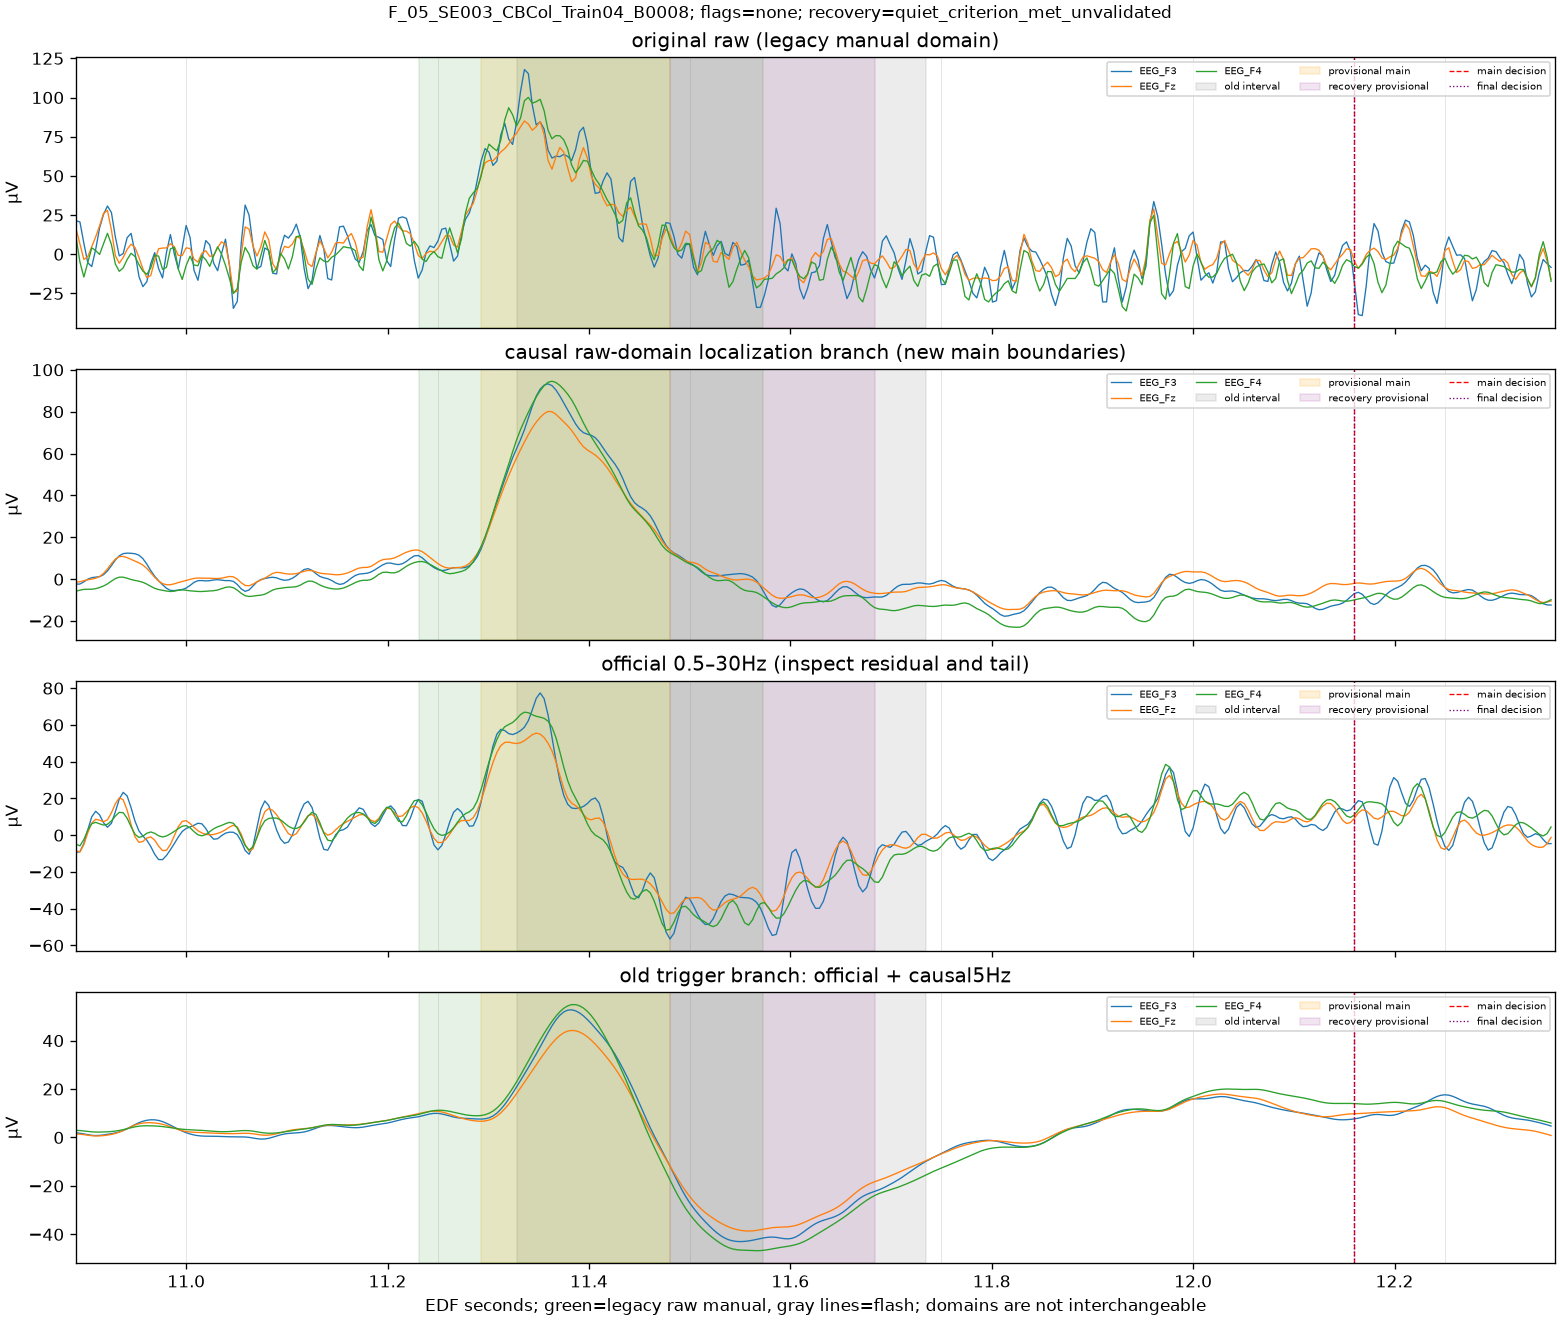

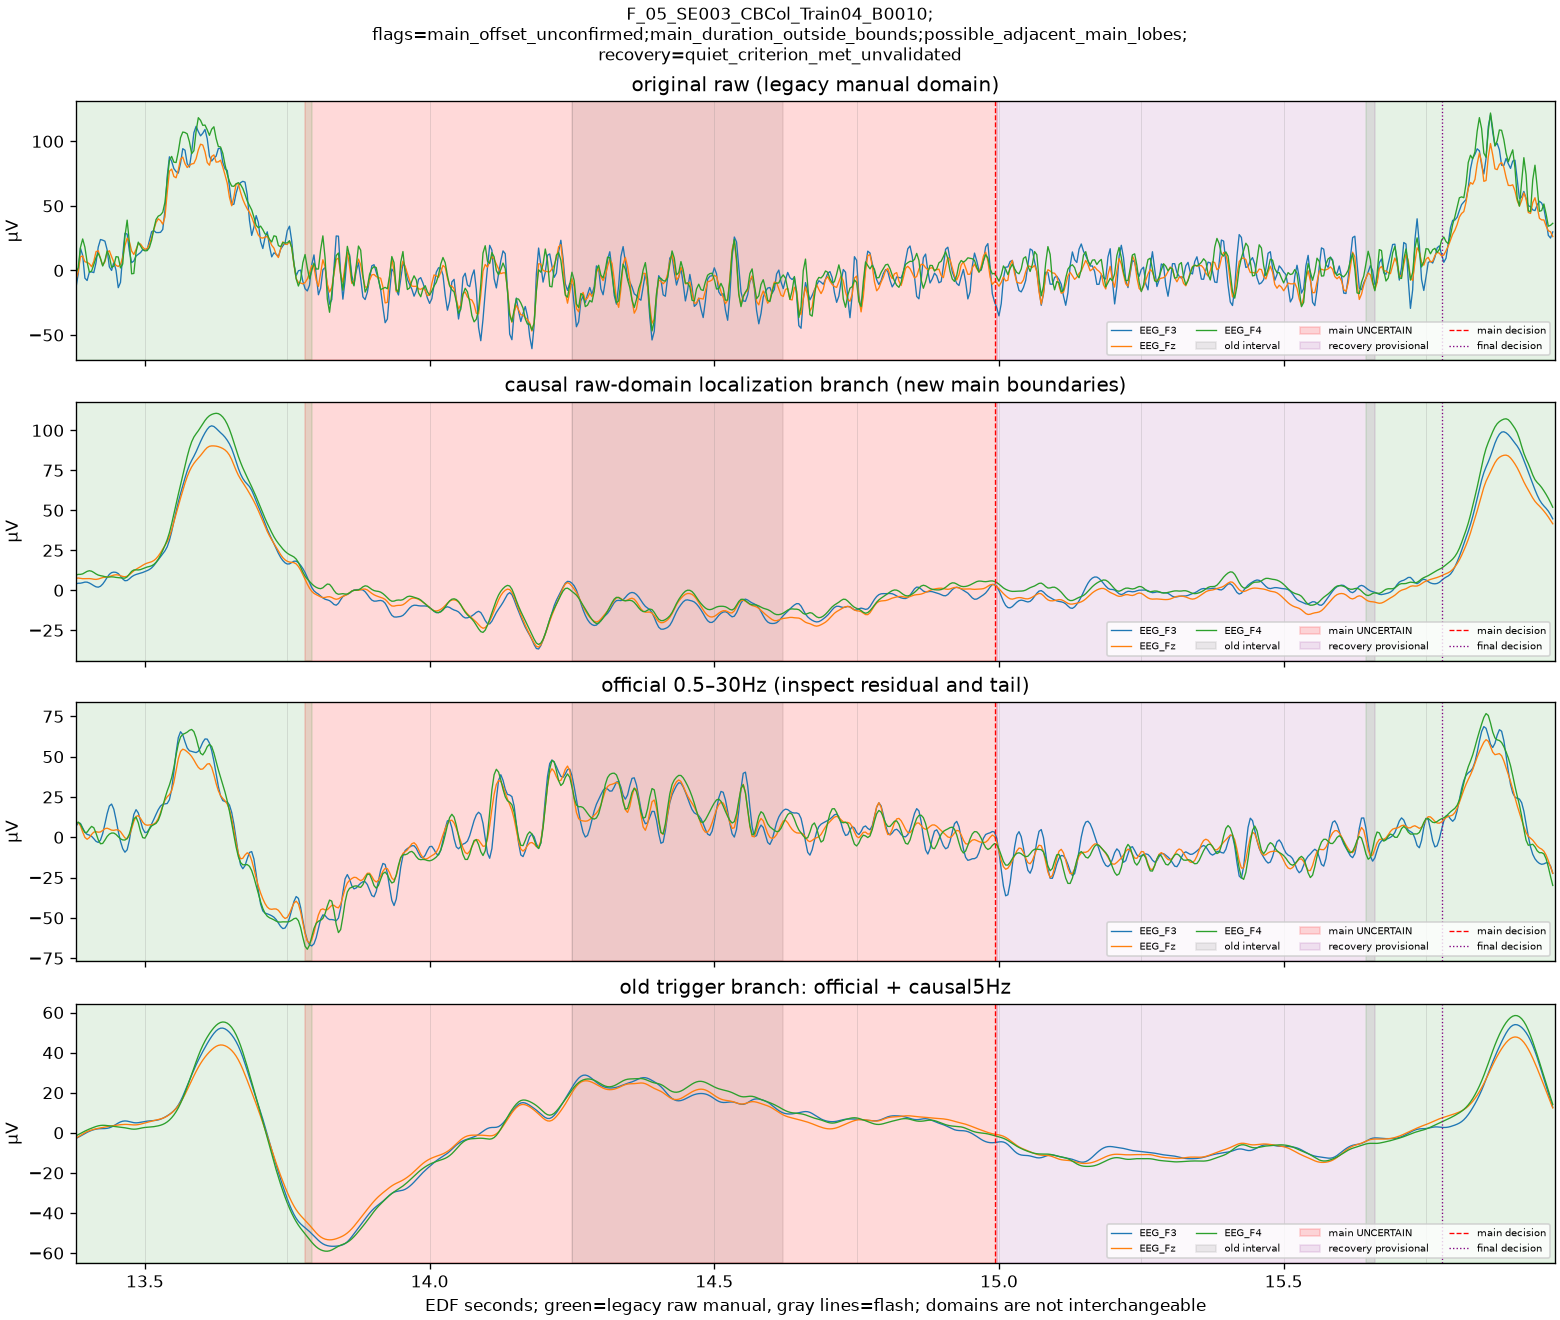

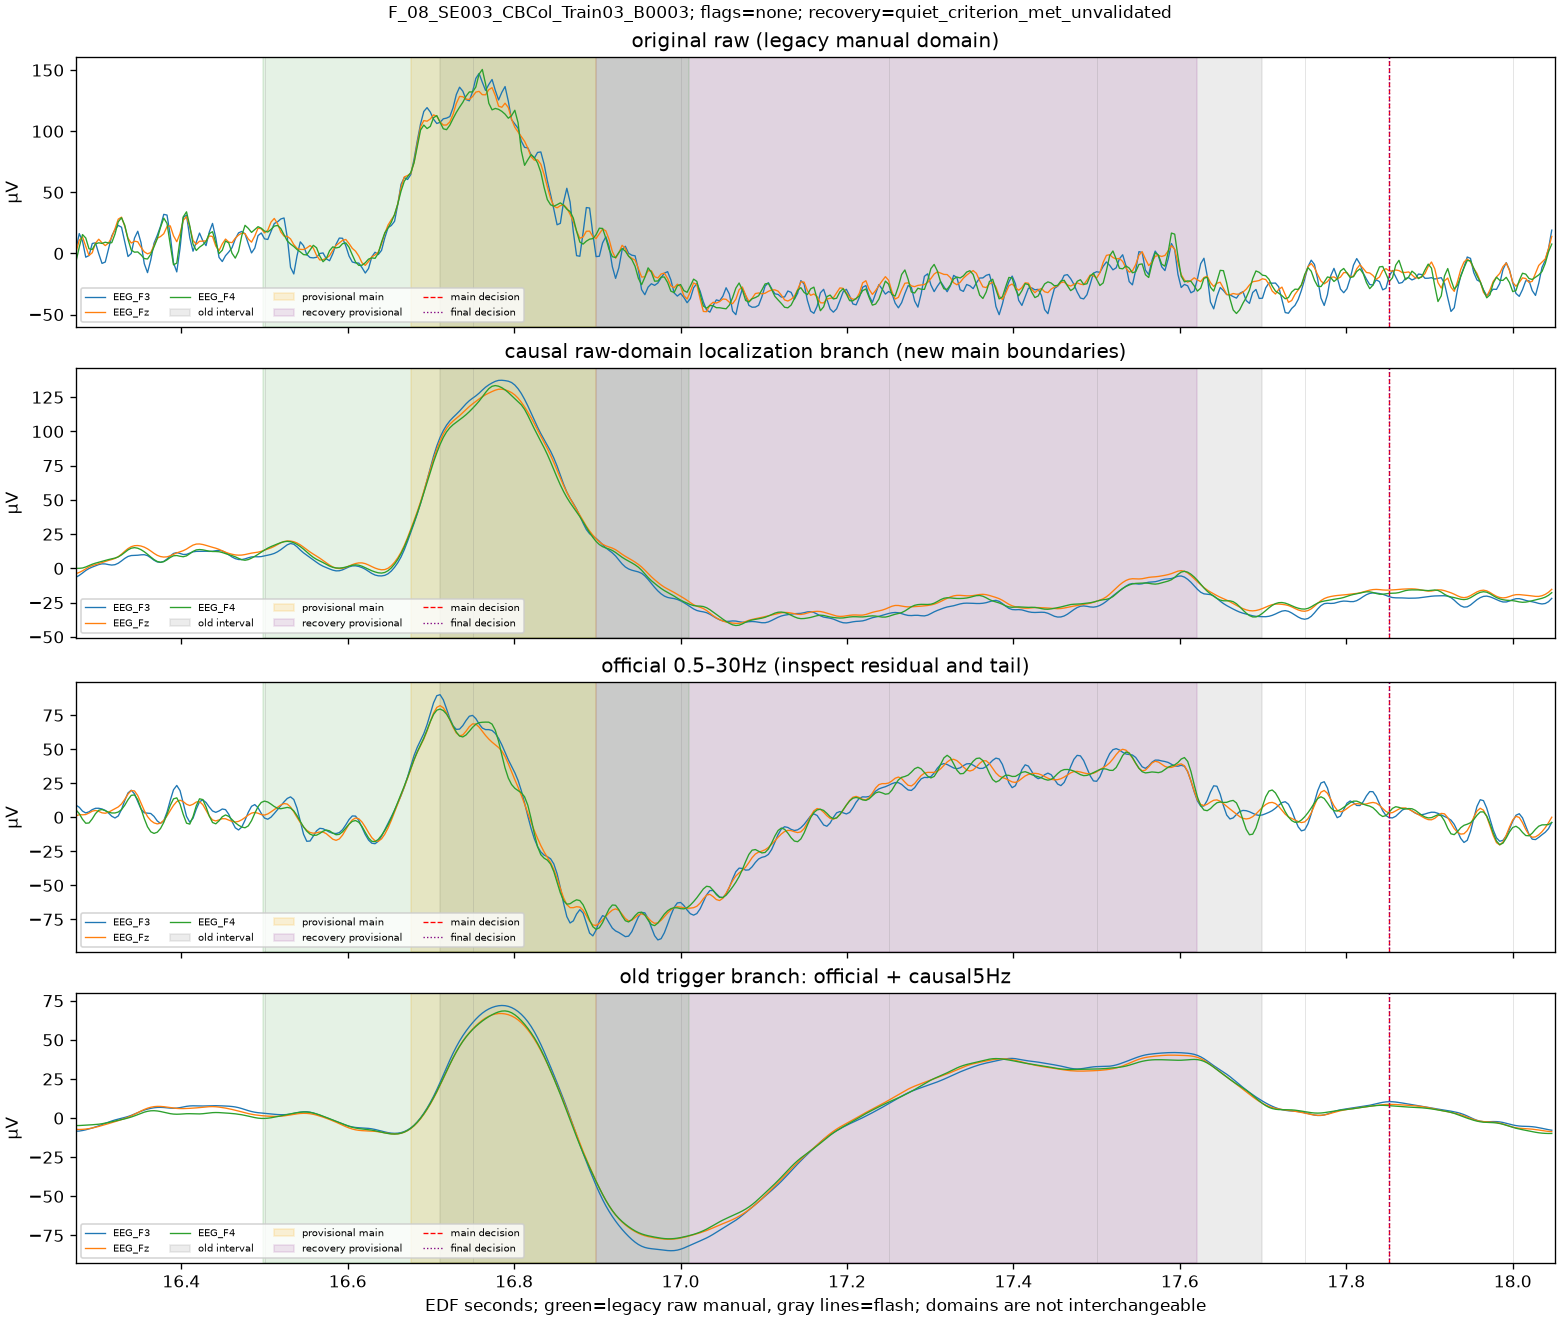

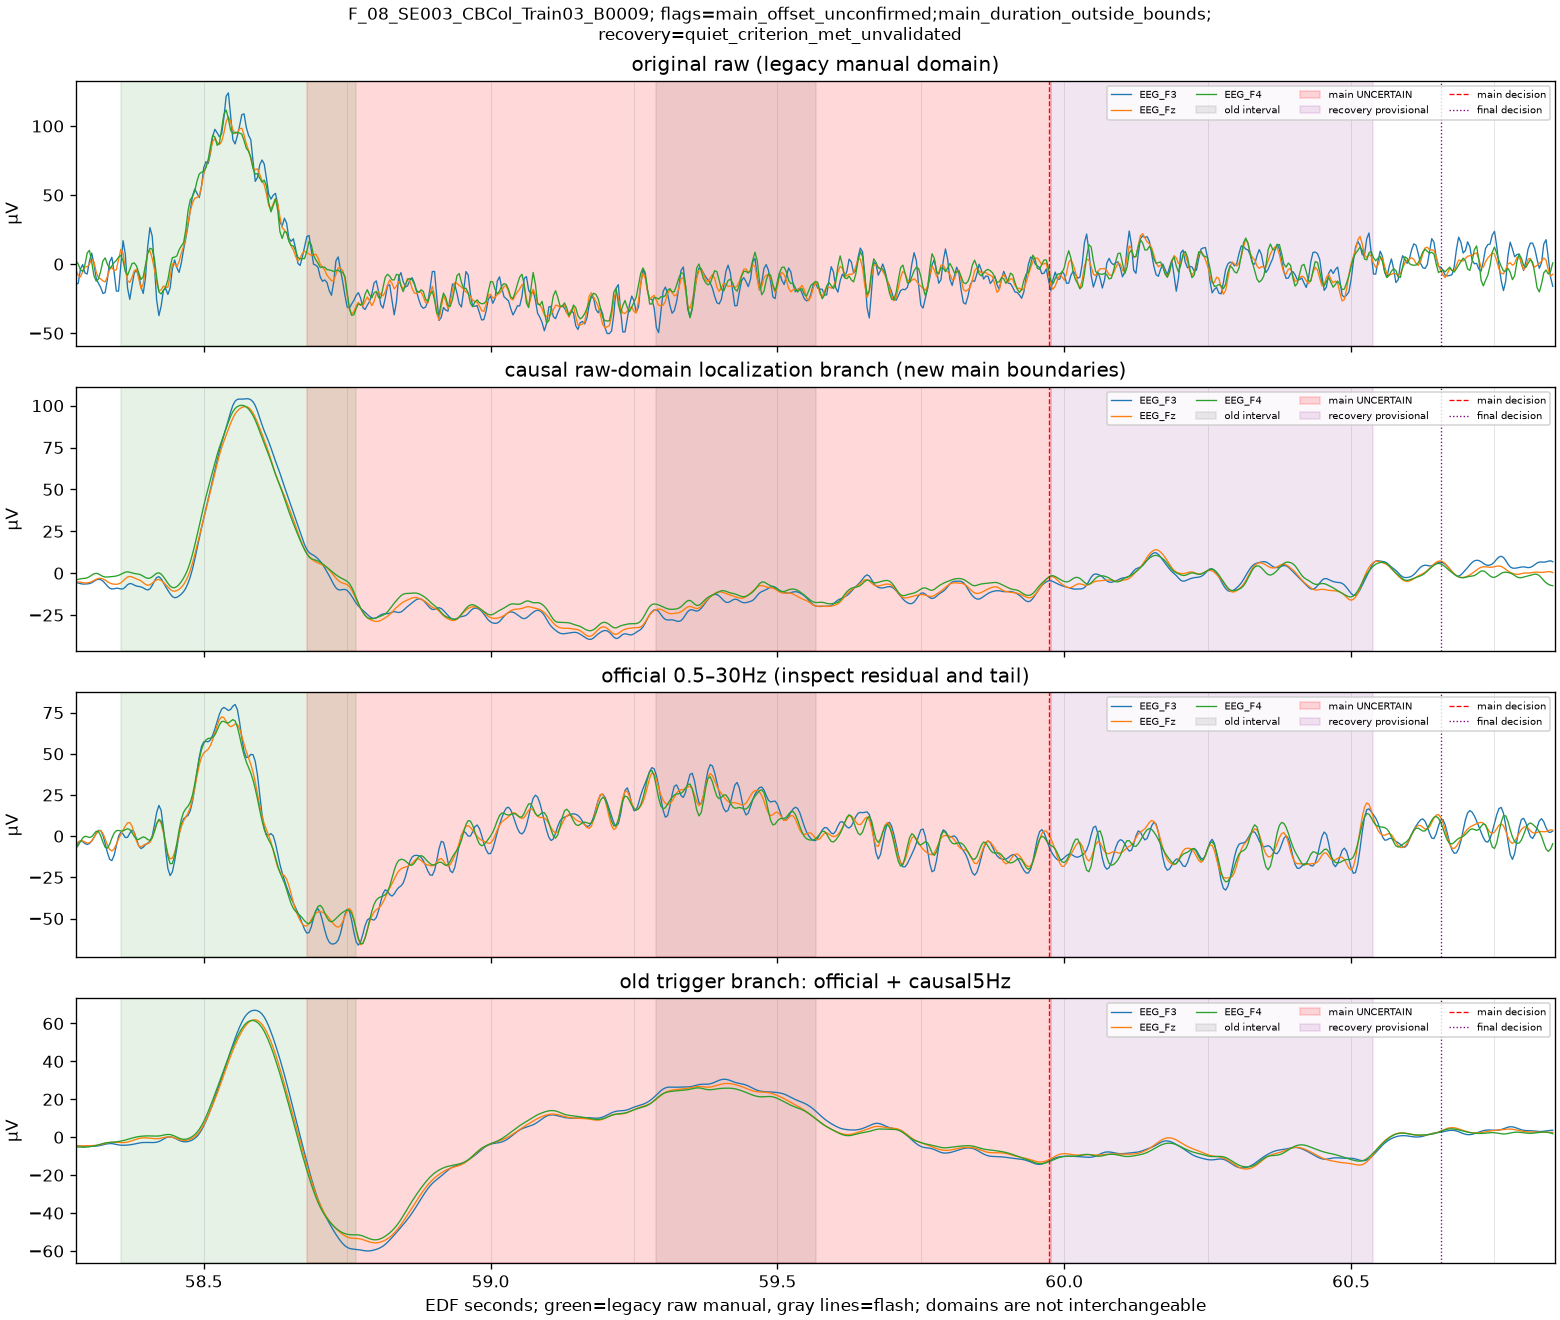

In [8]:
examples=pd.read_csv(OUT/'plotted_examples.csv')
display(examples)
for name in examples.figure:display(Image(filename=str(OUT/name),width=1200))

## 7. 新旧epoch重叠量：不是污染epoch真值

所有策略共用先前faults_only的共同基础条件，12份训练EDF的9054条事件全部保存。比较旧候选区间、仅主波、主波+恢复；定位不确定者均按前述规则回退旧区间。

旧的2105条只能称为“通过基础条件、与旧候选区间重叠的epoch”。下面的新数量也只是候选区间重叠，不表示这些epoch必须拒绝。无任何真实删除、重参考、ICA或模型训练。

In [9]:
display(summary)
display(pd.read_csv(OUT/'epoch_set_changes.csv'))
perfile=pd.read_csv(OUT/'edf_summary.csv')
display(perfile.pivot(index='edf_name',columns='scheme',values='extra_interval_rejections'))

,scheme,total,kept,retention,extra_interval_rejections,pending_at_eof
0,faults_only,9054,8790,0.970842,0,0
1,main_only_with_old_fallback,9054,6943,0.766843,1847,0
2,main_plus_recovery_with_old_fallback,9054,6389,0.705655,2401,0
3,old_candidate_overlap,9054,6685,0.738348,2105,0


,scheme,newly_kept_vs_old,newly_flagged_vs_old
0,main_only_with_old_fallback,344,86
1,main_plus_recovery_with_old_fallback,64,360


scheme,faults_only,main_only_with_old_fallback,main_plus_recovery_with_old_fallback,old_candidate_overlap
edf_name,,,,
F_03_SE001_CBCol_Train01.edf,0,0,2,0
F_03_SE002_CBCol_Train01.edf,0,10,16,11
F_05_SE001_CBCol_Train02.edf,0,296,440,329
F_05_SE002_CBCol_Train01.edf,0,348,457,406
F_05_SE002_CBCol_Train02.edf,0,417,518,500
F_05_SE003_CBCol_Train04.edf,0,447,563,496
F_06_SE001_CBCol_Train01.edf,0,0,0,0
F_06_SE002_CBCol_Train01.edf,0,0,0,0
F_08_SE003_CBCol_Train03.edf,0,90,107,111


**本轮结果：**旧区间标记2105条；仅主波（不确定回退）1847条；主波+恢复（不确定回退）2401条。主波方案净减少258条，但因为回溯起点向前移动，新旧集合不是严格包含关系，需看newly_kept/newly_flagged两列。

加入恢复后比旧方案多标记296条，说明把主波缩短不能自动推导信号更早可用。这是固定恢复工程条件下的结果，不应按保留率反向选择参数。

## 8. 类别、字符与刺激组

标签仅用于分组统计，不参与触发或定位。每字符有效flash仍只是对应方案下预计保留数，未定义字符评分/动态停止。刺激组沿用实际字符通道集合签名，不猜行列语义。

In [10]:
display(pd.read_csv(OUT/'subject_summary.csv'))
labels=pd.read_csv(OUT/'label_summary.csv')
display(labels[labels.edf_name.eq('F_05_SE003_CBCol_Train04.edf')])
chars=pd.read_csv(OUT/'character_summary.csv')
display(chars[chars.edf_name.eq('F_05_SE003_CBCol_Train04.edf')])
print('完整刺激集合计数：',OUT/'stimulus_group_summary.csv')

,scheme,subject_id,total,kept,retention,extra_interval_rejections,pending_at_eof
0,faults_only,F_03,1512,1468,0.970899,0,0
1,faults_only,F_05,3024,2936,0.970899,0,0
2,faults_only,F_06,1512,1468,0.970899,0,0
3,faults_only,F_08,756,734,0.970899,0,0
4,faults_only,F_20,1494,1450,0.970549,0,0
5,faults_only,F_25,756,734,0.970899,0,0
6,main_only_with_old_fallback,F_03,1512,1458,0.964286,10,0
7,main_only_with_old_fallback,F_05,3024,1428,0.472222,1508,0
8,main_only_with_old_fallback,F_06,1512,1468,0.970899,0,0
9,main_only_with_old_fallback,F_08,756,644,0.851852,90,0


,scheme,edf_name,label,total,kept,retention,extra_interval_rejections,pending_at_eof
10,faults_only,F_05_SE003_CBCol_Train04.edf,non-target,672,652,0.970238,0,0
11,faults_only,F_05_SE003_CBCol_Train04.edf,target,84,82,0.976190,0,0
34,main_only_with_old_fallback,F_05_SE003_CBCol_Train04.edf,non-target,672,283,0.421131,369,0
35,main_only_with_old_fallback,F_05_SE003_CBCol_Train04.edf,target,84,4,0.047619,78,0
58,main_plus_recovery_with_old_fallback,F_05_SE003_CBCol_Train04.edf,non-target,672,168,0.250000,484,0
59,main_plus_recovery_with_old_fallback,F_05_SE003_CBCol_Train04.edf,target,84,3,0.035714,79,0
82,old_candidate_overlap,F_05_SE003_CBCol_Train04.edf,non-target,672,233,0.346726,419,0
83,old_candidate_overlap,F_05_SE003_CBCol_Train04.edf,target,84,5,0.059524,77,0


,scheme,edf_name,character_trial_id,total,kept,retention,extra_interval_rejections,pending_at_eof
30,faults_only,F_05_SE003_CBCol_Train04.edf,1,126,104,0.825397,0,0
31,faults_only,F_05_SE003_CBCol_Train04.edf,2,126,126,1.000000,0,0
32,faults_only,F_05_SE003_CBCol_Train04.edf,3,126,126,1.000000,0,0
33,faults_only,F_05_SE003_CBCol_Train04.edf,4,126,126,1.000000,0,0
34,faults_only,F_05_SE003_CBCol_Train04.edf,5,126,126,1.000000,0,0
35,faults_only,F_05_SE003_CBCol_Train04.edf,6,126,126,1.000000,0,0
102,main_only_with_old_fallback,F_05_SE003_CBCol_Train04.edf,1,126,45,0.357143,59,0
103,main_only_with_old_fallback,F_05_SE003_CBCol_Train04.edf,2,126,52,0.412698,74,0
104,main_only_with_old_fallback,F_05_SE003_CBCol_Train04.edf,3,126,61,0.484127,65,0
105,main_only_with_old_fallback,F_05_SE003_CBCol_Train04.edf,4,126,44,0.349206,82,0


完整刺激集合计数： d:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_boundary_localization_v1\stimulus_group_summary.csv


## 9. 在线可用时间与待定

main_decision_seconds包含旧检测确认、峰搜索、主波结束确认及峰后多波审计所需观察；decision_seconds再包含恢复观察。actual_decision_seconds仅在数据真正到齐时提供，不能用回溯main_onset_seconds替代。

对“没有候选重叠”也需要保守等待：因为稍后的触发可回溯到当前epoch。新对照方案采用固定3.824秒左右的额外确认窗口，覆盖最大回溯与前向观察。它只是避免偷看未来的保守对照，**不是推荐在线等待时间**。本轮尚未优化增量调度/最早判定，也没有训练分类器；EOF待定另存，不假装已知无眨眼。

In [11]:
display(b[['blink_candidate_id','trigger_crossing_seconds','main_onset_seconds','main_decision_seconds','decision_seconds','decision_available','actual_decision_seconds']].head(12))
display(audit[['edf_name','new_policy_conservative_extra_wait_seconds']])
display(summary[['scheme','pending_at_eof']])

,blink_candidate_id,trigger_crossing_seconds,main_onset_seconds,main_decision_seconds,decision_seconds,decision_available,actual_decision_seconds
0,F_03_SE001_CBCol_Train01_B0001,1.414062,0.769531,2.207031,2.867188,True,2.867188
1,F_03_SE001_CBCol_Train01_B0002,108.761719,108.171875,109.507812,109.906250,True,109.906250
2,F_03_SE001_CBCol_Train01_B0003,212.421875,212.351562,213.414062,213.414062,True,213.414062
3,F_03_SE002_CBCol_Train01_B0001,0.140625,0.062500,1.148438,1.812500,True,1.812500
4,F_03_SE002_CBCol_Train01_B0002,0.500000,0.062500,1.148438,1.812500,True,1.812500
5,F_03_SE002_CBCol_Train01_B0003,4.191406,3.789062,4.890625,4.890625,True,4.890625
6,F_03_SE002_CBCol_Train01_B0004,87.410156,87.359375,88.281250,88.339844,True,88.339844
7,F_03_SE002_CBCol_Train01_B0005,106.148438,106.132812,107.093750,107.093750,True,107.093750
8,F_03_SE002_CBCol_Train01_B0006,126.917969,126.625000,127.519531,127.875000,True,127.875000
9,F_05_SE001_CBCol_Train02_B0001,2.042969,1.976562,2.863281,2.863281,True,2.863281


,edf_name,new_policy_conservative_extra_wait_seconds
0,F_03_SE001_CBCol_Train01.edf,3.824219
1,F_03_SE002_CBCol_Train01.edf,3.824219
2,F_05_SE001_CBCol_Train02.edf,3.824219
3,F_05_SE002_CBCol_Train01.edf,3.824219
4,F_06_SE001_CBCol_Train01.edf,3.824219
5,F_06_SE002_CBCol_Train01.edf,3.824219
6,F_20_SE001_CBCol_Train01.edf,3.824219
7,F_20_SE002_CBCol_Train01.edf,3.824219
8,F_05_SE002_CBCol_Train02.edf,3.824219
9,F_05_SE003_CBCol_Train04.edf,3.824219


,scheme,pending_at_eof
0,faults_only,0
1,main_only_with_old_fallback,0
2,main_plus_recovery_with_old_fallback,0
3,old_candidate_overlap,0


## 10. 旧人工边界不能直接用作新分支定位真值

下面只沿用旧父候选与人工的相交配对，列出旧/新边界与历史人工边界之差；不通过重新匹配来提高表面成绩，不做平均偏移校正。

三者的信号域明确分开：manual=原始EDF，old=正式+5Hz，new=原始+10Hz。这些delta仅描述，不报告为定位误差或证明新边界准确。要得到可比真值，请在下一节选择localization模式，独立标注所见主波边界，并记录信号域；正式分析尾波需在analysis模式另核查。

In [12]:
manual=pd.read_csv(OUT/'legacy_manual_domain_comparison.csv')
display(manual.head(12))

,edf_name,manual_id,blink_candidate_id,manual_start_sec,manual_end_sec,manual_domain,old_domain,new_domain,old_onset_delta,old_offset_delta,new_onset_delta,new_offset_delta,new_main_usable,interpretation
0,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0001,F_05_SE001_CBCol_Train02_B0001,1.889938,2.193431,original raw EEG,official+causal5Hz,raw+causal10Hz,0.153031,0.251881,0.086625,0.001881,True,descriptive domain mismatch; not boundary accu...
1,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0002,F_05_SE001_CBCol_Train02_B0002,2.903883,3.248762,original raw EEG,official+causal5Hz,raw+causal10Hz,-0.271070,0.266863,-0.720289,-0.264387,True,descriptive domain mismatch; not boundary accu...
2,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0003,F_05_SE001_CBCol_Train02_B0003,3.828159,4.221321,original raw EEG,official+causal5Hz,raw+causal10Hz,0.093716,0.118523,0.062466,-0.154915,True,descriptive domain mismatch; not boundary accu...
3,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0004,F_05_SE001_CBCol_Train02_B0005,10.139447,10.470531,original raw EEG,official+causal5Hz,raw+causal10Hz,0.122271,0.138844,0.051959,-0.107250,True,descriptive domain mismatch; not boundary accu...
4,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0005,F_05_SE001_CBCol_Train02_B0006,18.192551,18.499973,original raw EEG,official+causal5Hz,raw+causal10Hz,0.162917,0.132839,0.065261,-0.042942,True,descriptive domain mismatch; not boundary accu...
5,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0006,F_05_SE001_CBCol_Train02_B0011,31.747137,32.095549,original raw EEG,official+causal5Hz,raw+causal10Hz,0.198175,0.158357,-0.188544,-0.060393,False,descriptive domain mismatch; not boundary accu...
6,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0007,F_05_SE001_CBCol_Train02_B0012,37.410534,37.854588,original raw EEG,official+causal5Hz,raw+causal10Hz,0.269154,0.746975,0.237904,-0.120213,True,descriptive domain mismatch; not boundary accu...
7,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0008,F_05_SE001_CBCol_Train02_B0015,42.868982,43.121752,original raw EEG,official+causal5Hz,raw+causal10Hz,0.154455,0.202467,0.107580,-0.016283,True,descriptive domain mismatch; not boundary accu...
8,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0009,F_05_SE001_CBCol_Train02_B0016,50.760781,50.974606,original raw EEG,official+causal5Hz,raw+causal10Hz,0.098594,0.201175,0.075157,-0.041012,True,descriptive domain mismatch; not boundary accu...
9,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0010,F_05_SE001_CBCol_Train02_B0017,52.147195,52.512767,original raw EEG,official+causal5Hz,raw+causal10Hz,0.177024,0.080983,0.110617,-0.063548,True,descriptive domain mismatch; not boundary accu...


## 11. 独立交互核查窗口（不影响11号复核）

设置文件、mode和起点后，将OPEN_BOUNDARY_BROWSER=True再运行。mode可为raw、localization、analysis、auxiliary。灰色旧、橙色暂定主波、紫色恢复、红色定位不确定；历史人工为绿色。

如果要标可比主波边界：选择localization，按a新建BOUNDARY_MANUAL_main；恢复可在analysis上标BOUNDARY_MANUAL_recovery，不确定用BOUNDARY_MANUAL_uncertain。保存单元单独写新目录，记录mode，不覆盖11中的多检决定或旧人工标注。没有标记会明确报错而不存空文件。这里不要用BAD表示主波边界，BAD仍是11号窗口的“多检”语义。

In [17]:
if str(ROOT/'src') not in sys.path:sys.path.insert(0,str(ROOT/'src'))
from bigp3bci_boundary_review import open_boundary_review,save_domain_manual_boundaries
EDF='F_05_SE003_CBCol_Train04.edf'
BOUNDARY_MODE='localization'
BOUNDARY_START_SECONDS=10.5
OPEN_BOUNDARY_BROWSER=True
if OPEN_BOUNDARY_BROWSER:
    get_ipython().run_line_magic('matplotlib','qt')
    import mne
    mne.viz.set_browser_backend('matplotlib')
    boundary_raw,boundary_browser,boundary_table=open_boundary_review(ROOT,EDF,BOUNDARY_MODE,BOUNDARY_START_SECONDS)
else:
    print('需要时将OPEN_BOUNDARY_BROWSER设为True；无需关闭11号窗口或重新初始化其面板。')

In [14]:
SAVE_DOMAIN_BOUNDARIES=False
if SAVE_DOMAIN_BOUNDARIES:
    print(save_domain_manual_boundaries(ROOT,boundary_raw))

## 12. 一致性检查与后续证据

23项回归测试通过，新增检查历史回溯、未来数据不能改变已完成边界、正负极性、相邻峰只标记不静默合并、定位失败回退旧区间。源EDF及旧候选表hash前后一致；旧2105参考精确重现。

仍待验证：局部基线是否被前次眨眼影响、主波是否切短、真实相邻眨眼与反向波如何区分、恢复区间是否需要拒绝、分类效果以及同域人工真值。当前方法只是可复核的第一版定位，不能宣布完成伪迹去除。

运行：scripts/refine_blink_boundaries.py；配置：configs/blink_boundary_localization.json。所有时间端点均按样本半开区间保存；重叠时长按并集计算，不重复累计。

In [15]:
assert record['frozen_trigger_ids_preserved'] and record['old_candidate_files_unchanged']
assert record['old_policy_record_unchanged'] and not record['time_shift_correction']
assert len(b)==595 and b.blink_candidate_id.is_unique
assert (b.main_decision_seconds>=b.frozen_detector_decision_seconds).all()
assert (b.decision_seconds>=b.main_decision_seconds).all()
assert (b.recovery_onset_sample==b.main_offset_sample_exclusive).all()
assert (b.recovery_offset_sample_exclusive>=b.recovery_onset_sample).all()
assert b.loc[~b.decision_available,'actual_decision_seconds'].isna().all()
assert int(summary.loc[summary.scheme.eq('old_candidate_overlap'),'extra_interval_rejections'].iloc[0])==2105
assert summary.total.eq(9054).all()
print('PASS: frozen triggers and old results preserved; domains and decision availability explicit; old overlap count reproduced')

PASS: frozen triggers and old results preserved; domains and decision availability explicit; old overlap count reproduced
